# Experiment 8 · Does the direction of T2 split the reaction time?

**Date:** 2026-11-08 · **Agents:** the 19 competent `v2_catch` seeds · **Status:** group level, 19 seeds

## Question
Experiment 7 found that, with random geometry, seeing T2 slows the start of a short first
reach when T2 lies back the way the agent came, and speeds it when T2 continues onward. The
interpretation: the T2 plan leaks into the first push, so the two reaches compete when they
point in opposite directions. If that is right, then with the first reach held short:
1. RT on **reverse** trials should be reliably longer than on **continue** trials;
2. a block mixing both kinds should have a **bimodal** RT distribution, one mode per T2
   direction, while the same trials with T2 hidden should have one mode;
3. the effect should shrink for **long** first reaches (Experiment 7).

## Design
Two-target trials in which only the direction of T2 changes. Per geometry: start
x₀ ~ U[−0.5, 0.5], reach direction s = ±1, first-reach length d1, second-reach length
d2 ~ U[0.4, 0.6], and a go time from the training hold distribution (0.25–1.0 s).
T1 = x₀ + s·d1, and T2 = T1 + s·d2 (**continues**) or T1 − s·d2 (**reverses**), redrawn until
every point is inside ±0.9. Every geometry is played four times:

| | T2 visible from onset (H = 2) | T2 hidden until T1 is reached (H = 1) |
| --- | --- | --- |
| T2 continues | test | null |
| T2 reverses | test | null |

With T2 hidden, a continue trial and its reverse twin are *the same trial* up to T1, so their
RT difference is exactly 0. Two sets of geometries: **short** first reach (d1 ∈ [0.2, 0.3])
and **long** first reach (d1 ∈ [0.6, 0.8]). 400 geometries per set and seed, which is 3200
trials per seed. Noiseless plant and mean action; a check with motor noise on is at the end.

**RT** is force onset toward T1, as in Experiment 7: the force on the mass reaches 2 (25% of
u_max), interpolated, from the true go step, including the 80 ms cue delay.

**Why split by reach direction.** A pilot found that each seed starts leftward and rightward
reaches at different RTs, by up to 35 ms. That alone makes the pooled RT distribution
bimodal, even with T2 hidden. So bimodality is tested within each *cell* = seed × reach
direction (19 × 2 = 38 cells), where the hidden-T2 control is unimodal. The test is Hartigan's
dip test: a small p means the distribution is not unimodal.

In [1]:
from exp_tools import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import diptest
from IPython.display import display

use_style()
pd.set_option("display.precision", 3)
comp = pd.read_csv("exp06_task_drift.csv")
comp = comp[comp.group == "v2_catch"]
RUNS_V2 = comp[comp.competent].run.tolist()
print(len(RUNS_V2), "competent seeds")
SETS = {"short": (0.2, 0.3), "long": (0.6, 0.8)}
DCOL = {"continues": BLUE, "reverses": ORANGE, "hidden": INK_SOFT}

19 competent seeds


## Example: one geometry, T2 continuing or reversing (seed 3, short rightward first reach)

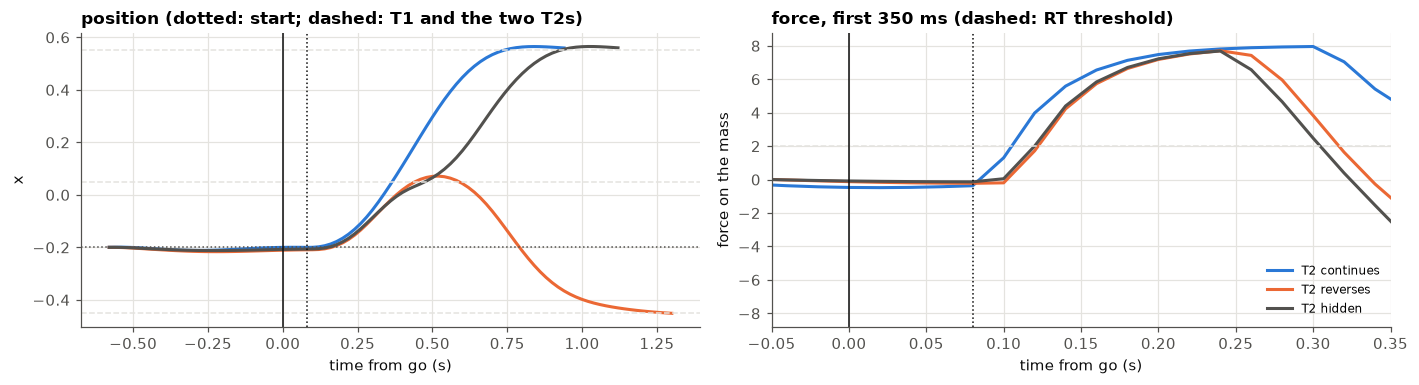

In [2]:
from seqreach import probes as _p
from seqreach.ppo import load_agent
agent, obs_rms, cfg = load_agent(RUNS / "v2_catch_s3")
pcfg = _p.probe_config(cfg)
x0, T1, d2, go = -0.2, 0.05, 0.5, 30   # start, short first reach to the right
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for lab, T2, H in [("T2 continues", T1 + d2, 2), ("T2 reverses", T1 - d2, 2), ("T2 hidden", T1 + d2, 1)]:
    tg = np.array([[T1, T2, T2]])
    tr = _p.rollout(agent, obs_rms, pcfg, {"n_targets": 2, "preview": H, "start_x": np.array([x0]),
                    "targets": tg, "delay_steps": go, "catch": np.array([False])}, n_trials=1)
    e = int(tr["end_step"][0]); tt = (np.arange(e + 1) - go + 1) * cfg.plant.dt  # state k = end of step k
    col = {"T2 continues": BLUE, "T2 reverses": ORANGE, "T2 hidden": INK_SOFT}[lab]
    axs[0].plot(tt, tr["x"][:e + 1, 0], color=col, lw=2, label=lab)
    axs[1].plot(tt, tr["a"][:e + 1, 0], color=col, lw=2, label=lab)
for v in (T1, T1 + d2, T1 - d2):
    axs[0].axhline(v, color=GRID, ls="--", lw=1)
axs[0].axhline(x0, color=INK_SOFT, ls=":", lw=1)
axs[1].set_xlim(-0.05, 0.35); axs[1].axhline(2, color=GRID, ls="--", lw=1)
for ax in axs:
    ax.axvline(0, color=INK, lw=1); ax.axvline(0.08, color=INK, ls=":", lw=1)
    ax.set_xlabel("time from go (s)")
axs[0].set_ylabel("x"); axs[1].set_ylabel("force on the mass")
axs[0].set_title("position (dotted: start; dashed: T1 and the two T2s)")
axs[1].set_title("force, first 350 ms (dashed: RT threshold)")
axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()

## Run all seeds

In [3]:
parts = []
for r in RUNS_V2:
    for name, d1 in SETS.items():
        df = direction_probe(RUNS / r, n_geom=400, d1=d1)
        df["run"], df["set"] = r, name
        parts.append(df)
trials = pd.concat(parts, ignore_index=True)
trials["reach_dir"] = np.where(trials.T1 > trials.x0, "right", "left")
print(len(trials), "trials; success rate", round(trials.success.mean(), 4),
      "| worst seed", round(trials.groupby("run").success.mean().min(), 4))

# The null by construction: with T2 hidden, continue and reverse twins are identical up to T1.
hid = trials[trials.visible == "hidden"].pivot_table(index=["run", "set", "geom"], columns="T2_dir", values="rt_ms")
print("hidden twins: max |RT(continue) - RT(reverse)| =", float((hid.continues - hid.reverses).abs().max()), "ms")

60800 trials; success rate 1.0 | worst seed 1.0
hidden twins: max |RT(continue) - RT(reverse)| = 0.0 ms


## 1 · Reverse vs continue: the paired test

Per geometry, ΔRT = RT(reverse) − RT(continue). The two trials have the same start, T1 and go
time; only T2's side differs. Per seed: the mean ΔRT, and a within-seed Wilcoxon signed-rank
test over its 400 geometries. Group: one mean per seed, Wilcoxon signed-rank across the
19 seeds, and a paired t-test for reference.

In [4]:
vis = trials[trials.visible == "visible"]
pair = vis.pivot_table(index=["run", "set", "reach_dir", "geom"], columns="T2_dir", values="rt_ms").dropna()
pair["d"] = pair.reverses - pair.continues
seed_d = pair.groupby(["set", "run"]).d.agg(["mean", "median"]).reset_index()
within = pair.groupby(["set", "run"]).d.apply(lambda x: stats.wilcoxon(x).pvalue).rename("p_within").reset_index()
seed_d = seed_d.merge(within)
rows = {}
for name in SETS:
    x = seed_d[seed_d.set == name]["mean"]
    rows[name + " first reach"] = {
        "mean ΔRT (ms)": x.mean(), "sd across seeds": x.std(), "seeds rev > cont": int((x > 0).sum()),
        "seeds sig. within (p<.05, rev>cont)": int(((seed_d.set == name) & (seed_d.p_within < .05) & (seed_d["mean"] > 0)).sum()),
        "seeds sig. within (p<.05, rev<cont)": int(((seed_d.set == name) & (seed_d.p_within < .05) & (seed_d["mean"] < 0)).sum()),
        "Wilcoxon p (19 seeds)": stats.wilcoxon(x).pvalue, "paired t p": stats.ttest_1samp(x, 0).pvalue}
xs, xl = (seed_d[seed_d.set == n].set_index("run")["mean"] for n in SETS)
rows["short − long (paired by seed)"] = {"mean ΔRT (ms)": (xs - xl).mean(), "sd across seeds": (xs - xl).std(),
                                         "seeds rev > cont": int(((xs - xl) > 0).sum()),
                                         "Wilcoxon p (19 seeds)": stats.wilcoxon(xs - xl).pvalue,
                                         "paired t p": stats.ttest_rel(xs, xl).pvalue}
main = pd.DataFrame(rows).T
main

,mean ΔRT (ms),sd across seeds,seeds rev > cont,"seeds sig. within (p<.05, rev>cont)","seeds sig. within (p<.05, rev<cont)",Wilcoxon p (19 seeds),paired t p
short first reach,14.655,12.617,17.0,17.0,2.0,1.907e-05,8.102e-05
long first reach,4.016,5.058,15.0,15.0,4.0,3.918e-03,2.788e-03
short − long (paired by seed),10.640,9.522,18.0,NaN,NaN,7.629e-06,1.230e-04


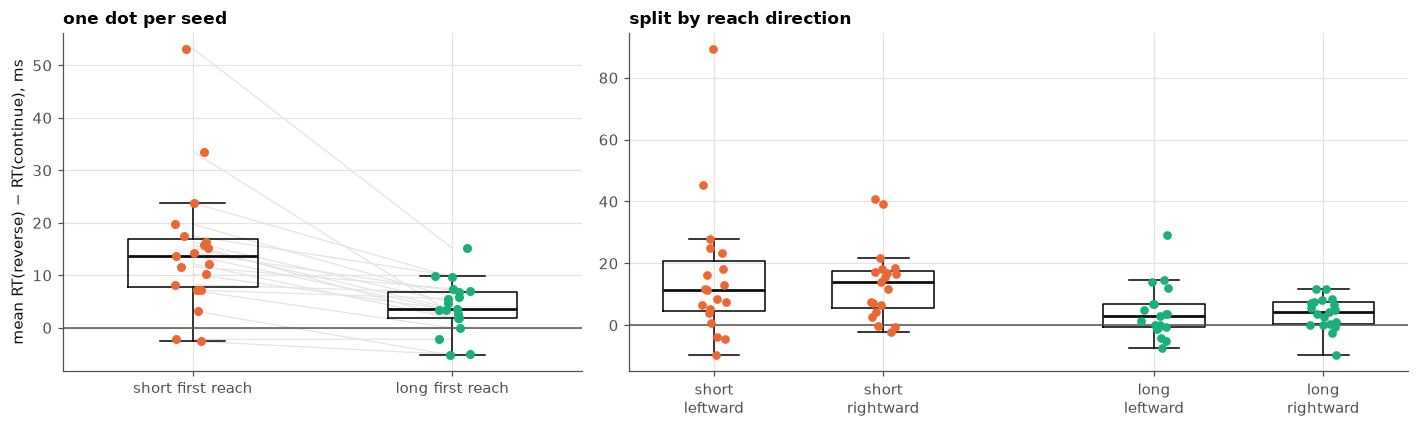

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 3]})
rng = np.random.default_rng(0)
for j, name in enumerate(SETS):
    y = seed_d[seed_d.set == name].set_index("run")["mean"]
    axs[0].boxplot([y], positions=[j], widths=0.5, showfliers=False,
                   medianprops=dict(color=INK, lw=1.8))
    axs[0].scatter(j + rng.uniform(-.07, .07, len(y)), y, color=[ORANGE, AQUA][j], s=24, zorder=3)
for r in RUNS_V2:
    axs[0].plot([0, 1], seed_d[seed_d.run == r].set_index("set").loc[["short", "long"], "mean"],
                color=GRID, lw=0.8, zorder=1)
axs[0].axhline(0, color=INK_SOFT, lw=1)
axs[0].set_xticks([0, 1], ["short first reach", "long first reach"])
axs[0].set_ylabel("mean RT(reverse) − RT(continue), ms"); axs[0].set_title("one dot per seed")
# the same, split by reach direction (each seed twice)
cell = pair.groupby(["set", "run", "reach_dir"]).d.mean().unstack("reach_dir")
for j, name in enumerate(SETS):
    for k, rd in enumerate(["left", "right"]):
        y = cell.loc[name][rd]
        pos = j * 2.6 + k
        axs[1].boxplot([y], positions=[pos], widths=0.6, showfliers=False, medianprops=dict(color=INK, lw=1.8))
        axs[1].scatter(pos + rng.uniform(-.08, .08, len(y)), y, color=[ORANGE, AQUA][j], s=22, zorder=3)
axs[1].set_xticks([0, 1, 2.6, 3.6], ["short\nleftward", "short\nrightward", "long\nleftward", "long\nrightward"])
axs[1].axhline(0, color=INK_SOFT, lw=1); axs[1].set_title("split by reach direction")
plt.tight_layout(); plt.show()

### Against the hidden twin

Which way does seeing T2 push each kind of trial? ΔRT = RT(T2 visible) − RT(T2 hidden),
for the same geometry. Mean per seed, Wilcoxon across seeds.

In [6]:
tw = trials.pivot_table(index=["run", "set", "geom", "T2_dir"], columns="visible", values="rt_ms").dropna()
tw["d"] = tw.visible - tw.hidden
tws = tw.groupby(["set", "T2_dir", "run"]).d.mean()
pd.DataFrame({f"{s} · T2 {d}": {"mean (ms)": tws.loc[s, d].mean(), "seeds > 0": int((tws.loc[s, d] > 0).sum()),
                                 "Wilcoxon p": stats.wilcoxon(tws.loc[s, d]).pvalue}
              for s in SETS for d in ["continues", "reverses"]}).T

,mean (ms),seeds > 0,Wilcoxon p
short · T2 continues,-7.403,3.0,1.411e-03
short · T2 reverses,7.252,18.0,1.144e-05
long · T2 continues,-3.778,5.0,1.083e-02
long · T2 reverses,0.238,10.0,7.983e-01


## 2 · Is the RT distribution bimodal?

Within each cell (seed × reach direction), short first reaches: the RTs of a block that mixes
continue and reverse trials (T2 visible), against the same trials with T2 hidden. Dip test
on each.

In [7]:
def dip_p(x):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    return diptest.diptest(x)[1] if len(x) > 10 else np.nan

def bimod_table(name):
    rows = []
    for (r, rd), g in trials[trials.set == name].groupby(["run", "reach_dir"]):
        v, h = g[g.visible == "visible"], g[g.visible == "hidden"]
        c, rv = v[v.T2_dir == "continues"].rt_ms, v[v.T2_dir == "reverses"].rt_ms
        pooled_sd = np.sqrt((c.var() + rv.var()) / 2)
        rows.append({"run": r, "reach_dir": rd, "n": len(v),
                     "med_cont": c.median(), "med_rev": rv.median(), "med_hidden": h.rt_ms.median(),
                     "separation (d')": (rv.mean() - c.mean()) / pooled_sd,
                     "dip_p_visible": dip_p(v.rt_ms), "dip_p_hidden": dip_p(h.rt_ms)})
    return pd.DataFrame(rows)

bim = {name: bimod_table(name) for name in SETS}
summ = {}
for name, b in bim.items():
    summ[name + " first reach"] = {
        "cells": len(b),
        "bimodal, T2 visible (dip p<.05)": int((b.dip_p_visible < .05).sum()),
        "bimodal, T2 hidden (dip p<.05)": int((b.dip_p_hidden < .05).sum()),
        "bimodal visible, unimodal hidden": int(((b.dip_p_visible < .05) & (b.dip_p_hidden >= .05)).sum()),
        "median separation d'": b["separation (d')"].median(),
        "cells with d' > 2": int((b["separation (d')"] > 2).sum())}
display(pd.DataFrame(summ).T)
b = bim["short"]
print("McNemar-style count, short reach: cells bimodal only when T2 is visible vs only when hidden:",
      int(((b.dip_p_visible < .05) & (b.dip_p_hidden >= .05)).sum()), "vs",
      int(((b.dip_p_visible >= .05) & (b.dip_p_hidden < .05)).sum()))
k_vis = int(((b.dip_p_visible < .05) & (b.dip_p_hidden >= .05)).sum())
k_hid = int(((b.dip_p_visible >= .05) & (b.dip_p_hidden < .05)).sum())
if k_vis + k_hid:
    print("exact binomial p =", round(stats.binomtest(k_vis, k_vis + k_hid).pvalue, 5))
bim["short"].sort_values("separation (d')", ascending=False).round(3)

,cells,"bimodal, T2 visible (dip p<.05)","bimodal, T2 hidden (dip p<.05)","bimodal visible, unimodal hidden",median separation d',cells with d' > 2
short first reach,38.0,18.0,6.0,16.0,2.589,22.0
long first reach,38.0,16.0,11.0,11.0,1.451,14.0


McNemar-style count, short reach: cells bimodal only when T2 is visible vs only when hidden: 16 vs 4
exact binomial p = 0.01182


,run,reach_dir,n,med_cont,med_rev,med_hidden,separation (d'),dip_p_visible,dip_p_hidden
2,v2_catch_s10,left,450,111.651,139.984,117.319,5.291,0.000,0.108
27,v2_catch_s3,right,350,105.627,122.563,120.602,4.859,0.000,0.683
31,v2_catch_s5,right,350,102.440,120.532,118.564,4.792,0.000,0.004
21,v2_catch_s19,right,350,93.924,111.900,106.037,4.682,0.000,0.597
22,v2_catch_s2,left,450,99.255,116.565,120.332,4.652,0.000,0.147
34,v2_catch_s8,left,450,98.912,110.745,104.251,4.648,0.000,0.859
23,v2_catch_s2,right,350,97.422,118.136,103.106,4.626,0.000,0.302
20,v2_catch_s19,left,450,99.921,144.417,114.060,4.368,0.000,0.537
19,v2_catch_s18,right,350,109.361,126.577,113.533,4.352,0.000,0.851
33,v2_catch_s6,right,350,101.565,117.382,105.632,4.135,0.000,0.005


### The 38 cells, short first reach

Each panel is one seed and reach direction. Blue: T2 continues; orange: T2 reverses (both visible, stacked: together they are the mixed-block distribution). Grey outline: the same trials with T2 hidden. Panels are sorted by how far apart the two modes are; the dip-test p for the mixed block is in the corner.

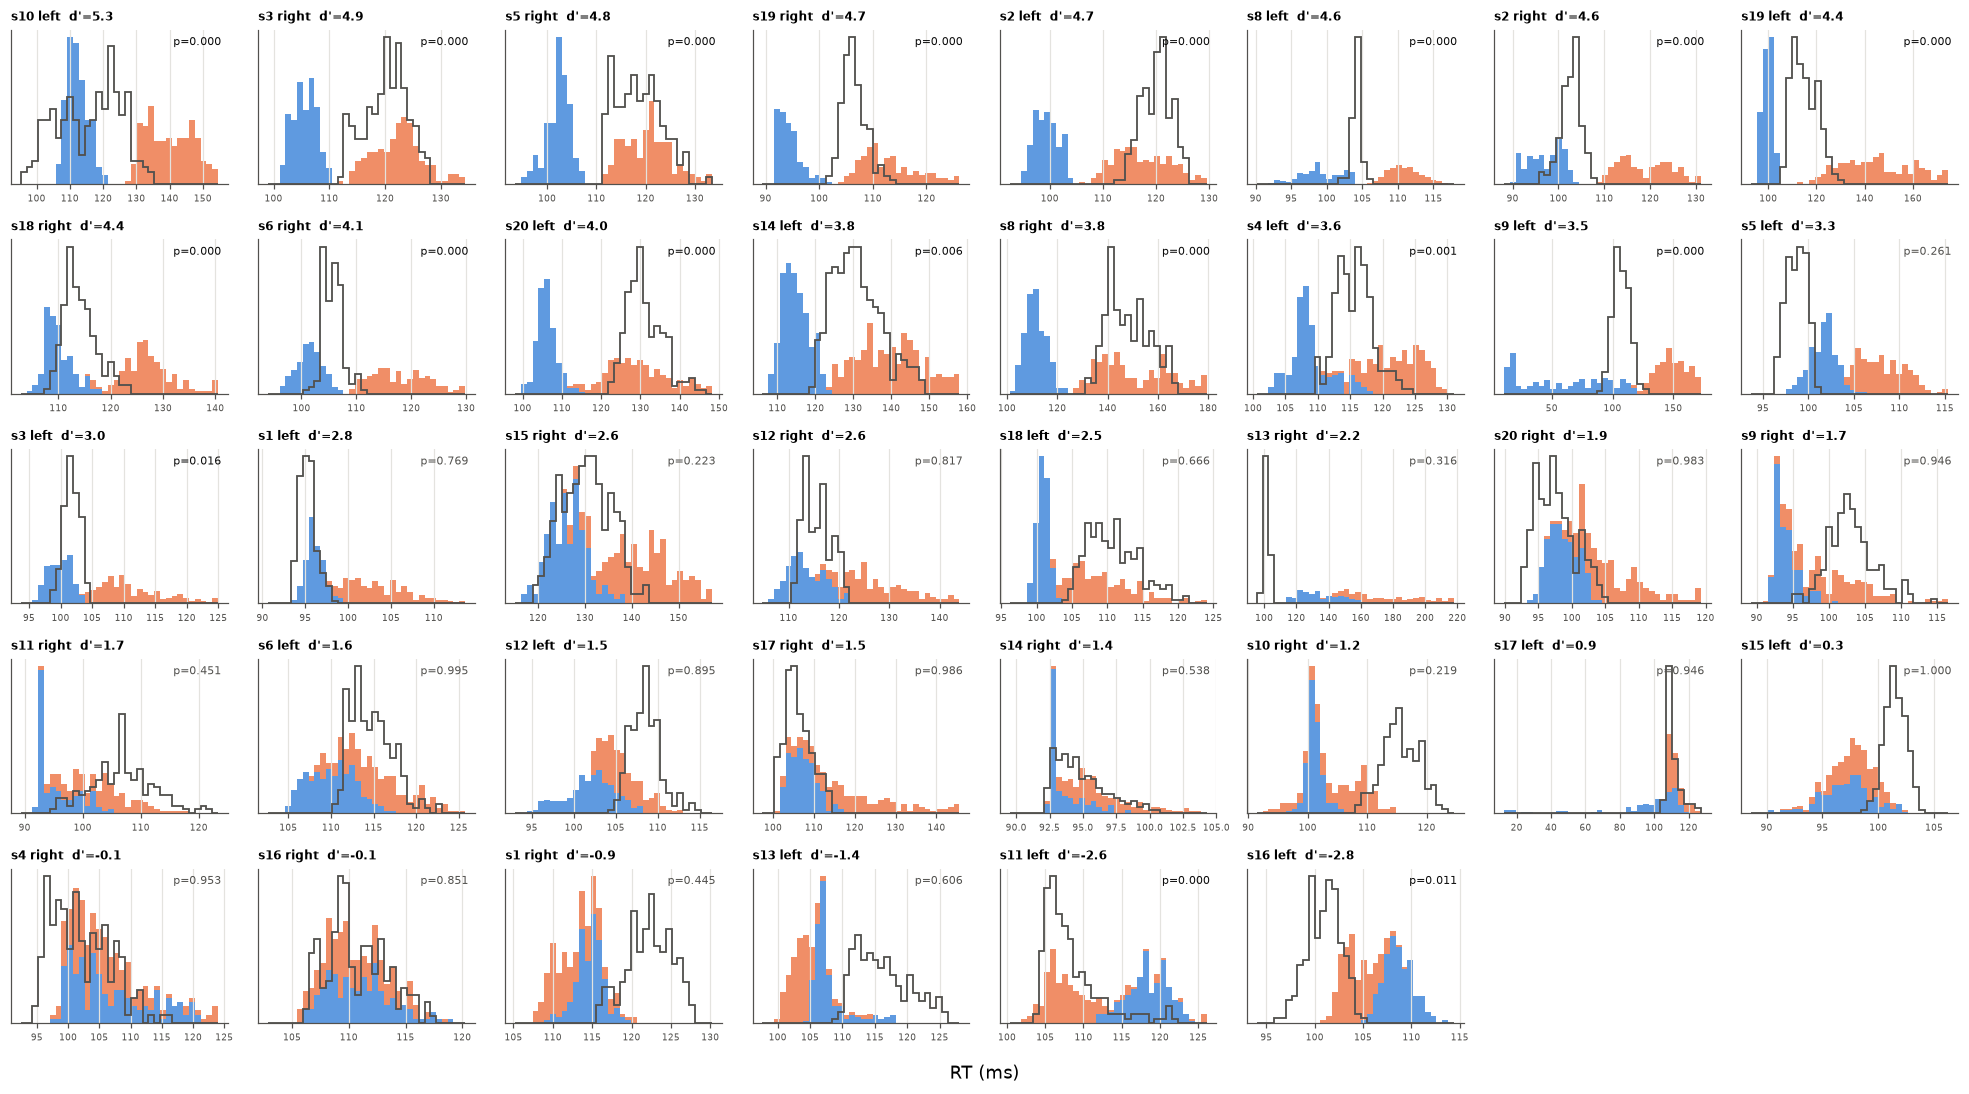

In [8]:
b = bim["short"].sort_values("separation (d')", ascending=False).reset_index(drop=True)
fig, axs = plt.subplots(5, 8, figsize=(18, 10))
for ax in axs.flat[len(b):]:
    ax.axis("off")
sub = trials[trials.set == "short"]
for ax, (_, row) in zip(axs.flat, b.iterrows()):
    g = sub[(sub.run == row.run) & (sub.reach_dir == row.reach_dir)]
    v, h = g[g.visible == "visible"], g[g.visible == "hidden"]
    lo, hi = np.nanpercentile(g.rt_ms, [0.5, 99]); lo, hi = lo - 3, hi + 3
    bins = np.linspace(lo, hi, 35)
    ax.hist([v[v.T2_dir == "continues"].rt_ms.clip(lo, hi), v[v.T2_dir == "reverses"].rt_ms.clip(lo, hi)],
            bins=bins, stacked=True, color=[BLUE, ORANGE], alpha=0.75)
    ax.hist(h.rt_ms.clip(lo, hi), bins=bins, histtype="step", color=INK_SOFT, lw=1.2)
    sep = row["separation (d')"]
    ax.set_title(f"{row.run.replace('v2_catch_', '')} {row.reach_dir}  d'={sep:.1f}", fontsize=8)
    ax.text(0.97, 0.9, f"p={row.dip_p_visible:.3f}", transform=ax.transAxes, ha="right", fontsize=7,
            color=INK if row.dip_p_visible < .05 else INK_SOFT)
    ax.tick_params(labelsize=6); ax.set_yticks([])
fig.supxlabel("RT (ms)"); plt.tight_layout(); plt.show()

### All cells together

Each trial's RT relative to its own cell's hidden-T2 median. This removes the seed-specific
and reach-direction-specific offsets, so cells can be pooled.

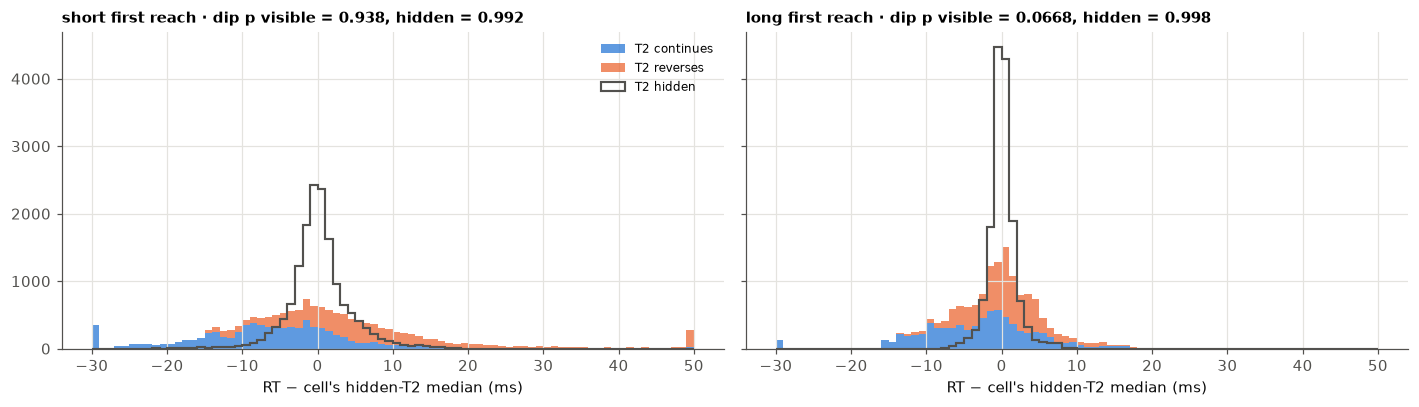

,"dip p, T2 visible","dip p, T2 hidden"
short,0.938,0.992
long,0.067,0.998


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
pooled = {}
for ax, name in zip(axs, SETS):
    sub = trials[trials.set == name].copy()
    ref = sub[sub.visible == "hidden"].groupby(["run", "reach_dir"]).rt_ms.median().rename("ref")
    sub = sub.join(ref, on=["run", "reach_dir"]); sub["rel"] = sub.rt_ms - sub.ref
    v, h = sub[sub.visible == "visible"], sub[sub.visible == "hidden"]
    bins = np.linspace(-30, 50, 81)
    ax.hist([v[v.T2_dir == "continues"].rel.clip(-30, 50), v[v.T2_dir == "reverses"].rel.clip(-30, 50)],
            bins=bins, stacked=True, color=[BLUE, ORANGE], alpha=0.75, label=["T2 continues", "T2 reverses"])
    ax.hist(h.rel.clip(-30, 50), bins=bins, histtype="step", color=INK_SOFT, lw=1.4, label="T2 hidden")
    pooled[name] = {"dip p, T2 visible": dip_p(v.rel), "dip p, T2 hidden": dip_p(h.rel)}
    ax.set_title(f"{name} first reach · dip p visible = {pooled[name]['dip p, T2 visible']:.3g}, hidden = {pooled[name]['dip p, T2 hidden']:.3g}", fontsize=10)
    ax.set_xlabel("RT − cell's hidden-T2 median (ms)")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
pd.DataFrame(pooled).T

## 3 · Wrong-way pushes

Fraction of trials with a push of the same size *away* from T1 (toward a reversing T2) before the response.

In [10]:
ww = trials.groupby(["set", "visible", "T2_dir", "run"]).wrong_way.mean()
tab = ww.groupby(["set", "visible", "T2_dir"]).agg(["mean", "max"])
tab["seeds with any"] = ww.groupby(["set", "visible", "T2_dir"]).apply(lambda x: int((x > 0).sum()))
tab

mean   max  seeds with any
set   visible T2_dir                                
long  hidden  continues  0.000  0.00               0
              reverses   0.000  0.00               0
      visible continues  0.028  0.27               3
              reverses   0.016  0.23               4
short hidden  continues  0.011  0.15               5
              reverses   0.011  0.15               5
      visible continues  0.026  0.26               4
              reverses   0.076  0.39              11

## 4 · Robustness: motor noise on

The same short-reach test with the plant's motor noise switched back on (the policy still takes its mean action), 200 geometries per seed.

In [11]:
nz = []
for r in RUNS_V2:
    df = direction_probe(RUNS / r, n_geom=200, d1=SETS["short"], noiseless=False, seed=99)
    p = df[df.visible == "visible"].pivot_table(index="geom", columns="T2_dir", values="rt_ms").dropna()
    nz.append({"run": r, "mean ΔRT": (p.reverses - p.continues).mean()})
nz = pd.DataFrame(nz)
print(f"noisy plant: mean ΔRT (rev − cont) = {nz['mean ΔRT'].mean():.1f} ms, "
      f"{int((nz['mean ΔRT'] > 0).sum())}/19 seeds > 0, Wilcoxon p = {stats.wilcoxon(nz['mean ΔRT']).pvalue:.2g}")

noisy plant: mean ΔRT (rev − cont) = 13.7 ms, 17/19 seeds > 0, Wilcoxon p = 2.7e-05


In [12]:
seed_d.to_csv("exp08_rev_minus_cont_per_seed.csv", index=False)
pd.concat({k: v for k, v in bim.items()}, names=["set"]).to_csv("exp08_bimodality_cells.csv")
print("saved")

saved


## Conclusion

**The test is valid.** All 60,800 trials succeed. With T2 hidden, every continue/reverse pair
has *exactly* the same RT (largest difference 0.0 ms), so any difference with T2 visible comes
from seeing where T2 is.

### 1. Reverse trials start later than continue trials: confirmed
| | mean RT(reverse) − RT(continue) | seeds with reverse slower | Wilcoxon p (19 seeds) | paired t p |
| --- | --- | --- | --- | --- |
| **short first reach** (0.2–0.3) | **+14.7 ms** (sd 12.6) | **17/19** | **1.9 × 10⁻⁵** | 8 × 10⁻⁵ |
| long first reach (0.6–0.8) | +4.0 ms (sd 5.1) | 15/19 | 0.004 | 0.003 |
| short − long | +10.6 ms | 18/19 | 7.6 × 10⁻⁶ | 1 × 10⁻⁴ |

- Within seeds, the effect is significant (p < .05 over 400 paired geometries) in 17 of 19 seeds
  for short reaches. The other 2 are significant in the *opposite* direction.
- Against the hidden twin, both halves of the prediction hold for short reaches. Seeing a
  continuing T2 **speeds** RT by 7.4 ms (16/19 seeds, p = 0.001), and seeing a reversing T2 **slows**
  it by 7.3 ms (18/19, p = 1 × 10⁻⁵). For long reaches only the speed-up remains (−3.8 ms,
  p = 0.01); a reversing T2 no longer slows the start (+0.2 ms, p = 0.80).
- **Wrong-way pushes** (a push away from T1, toward the reversing T2, before the response)
  happen in 7.6% of short reverse trials (11 of 19 seeds), against 2.6% for continue trials
  and 1.1% with T2 hidden.
- **The effect survives motor noise:** +13.7 ms, 17/19 seeds, p = 3 × 10⁻⁵.

### 2. Bimodality: yes within a seed, in about half the cells; no when pooled across seeds
- A cell is one seed × one reach direction. In each cell, a block mixing continue and reverse
  trials is bimodal (dip test p < .05) in **18 of 38** cells, against 6 of 38 for the same
  trials with T2 hidden.
- **16 cells are bimodal only when T2 is visible, and 4 only when it is hidden** (exact
  binomial p = 0.012).
- Where the two modes are far apart (d′ > 3.3), the RT is bimodal in **all 15** cells. There the
  continue trials form one tight cluster and the reverse trials a second, slower one, with
  the hidden-T2 distribution between or under them.
- In the remaining cells the two modes overlap and the dip test can't separate them.
- In 2 cells (s11 and s16 leftward) the RT is also bimodal, but the order is flipped:
  continue trials are slower.
- **Pooled across seeds, the RT is not bimodal** (dip p = 0.94), even after removing each cell's
  offset. Each seed puts its modes at different places and different distances apart, so the
  pooled histogram smears into one broad, right-skewed distribution.
- The *mean* shift is the robust group-level result (section 1). Bimodality is a
  within-individual property, visible in about half of them.

### 3. Interpretation
The prediction holds. When the first reach is short, the plan for T2 is already shaping the
first push at go:
- a T2 in the same direction adds drive, so the force builds faster;
- a T2 behind the start subtracts drive, so the force builds slower, and sometimes the agent
  pushes toward T2 first.

For a long first reach, the first reach dominates the command and T2 barely matters. Both
reaches are prepared together and add up in the same motor command. That is a motor
interaction between the elements, not a serial cost of planning more elements. It fits the
null sequence-length effect in Experiment 7.

**Caveat:** the direction effect differs in size between seeds and between leftward and
rightward reaches (each seed's policy is not mirror-symmetric). So any analysis of the
network's state should be done per seed and per reach direction, not on pooled data.
